In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# 1. Locate Experiment Directory
candidates = [
    Path.cwd(),
    Path.cwd() / "experiments" / "04_electricity",
    Path.cwd().parent / "experiments" / "04_electricity",
]

BASE_DIR = next(
    (
        p.resolve()
        for p in candidates
        if (
            p / "results" / "electricity_grid_search_e4000"
        ).is_dir()
    ),
    None
)

assert BASE_DIR is not None, (
    "Cannot locate Electricity experiment directory"
)

RESULTS_DIR = (
    BASE_DIR / "results" / "electricity_grid_search_e4000"
)

METRICS_PATH = RESULTS_DIR / "metrics.csv"

assert METRICS_PATH.is_file(), METRICS_PATH

# 2. Load Metrics
metrics_df = pd.read_csv(METRICS_PATH)

# 3. Verify Results
checkpoint_files = sorted(
    RESULTS_DIR.glob("*.pt")
)

print("=== ELECTRICITY RESULTS ===")

print("Results directory:", RESULTS_DIR)

print("\nCheckpoints:", len(checkpoint_files))
print("Metrics rows:", len(metrics_df))

print("\nModels:")
print(metrics_df["Model"].value_counts())

print("\nTrain/Test:")
print(metrics_df["Set"].value_counts())

print("\nPatch lengths:")
print(sorted(metrics_df["PatchLen"].unique()))

print("\nHorizons:")
print(sorted(metrics_df["Horizon"].unique()))

assert len(checkpoint_files) == 224
assert len(metrics_df) == 448

assert metrics_df["Model"].nunique() == 4
assert metrics_df["PatchLen"].nunique() == 7
assert metrics_df["Horizon"].nunique() == 8

assert not metrics_df[["MSE", "MAE"]].isna().any().any()

print("\nAll Electricity results validated!")

# 4. Preview Metrics
display(metrics_df.head(8))

=== ELECTRICITY RESULTS ===
Results directory: C:\Users\Win 11 New\Desktop\pa gk\experiments\04_electricity\results\electricity_grid_search_e4000

Checkpoints: 224
Metrics rows: 448

Models:
Model
LSTM          112
PatchTST      112
Autoformer    112
Informer      112
Name: count, dtype: int64

Train/Test:
Set
Train    224
Test     224
Name: count, dtype: int64

Patch lengths:
[70, 80, 90, 100, 110, 120, 130]

Horizons:
[2, 4, 6, 8, 10, 12, 14, 16]

All Electricity results validated!


,Model,PatchLen,Horizon,d_model,Set,Epochs,MSE,MAE
0,LSTM,70,2,96,Train,4000,0.002996,0.032692
1,LSTM,70,2,96,Test,4000,0.005746,0.046954
2,PatchTST,70,2,96,Train,4000,0.001641,0.024770
3,PatchTST,70,2,96,Test,4000,0.006367,0.048945
4,Autoformer,70,2,96,Train,4000,0.013236,0.086819
5,Autoformer,70,2,96,Test,4000,0.018254,0.103529
6,Informer,70,2,96,Train,4000,0.001429,0.023568
7,Informer,70,2,96,Test,4000,0.005950,0.046988


Electricity — Train MSE / MAE Heatmaps

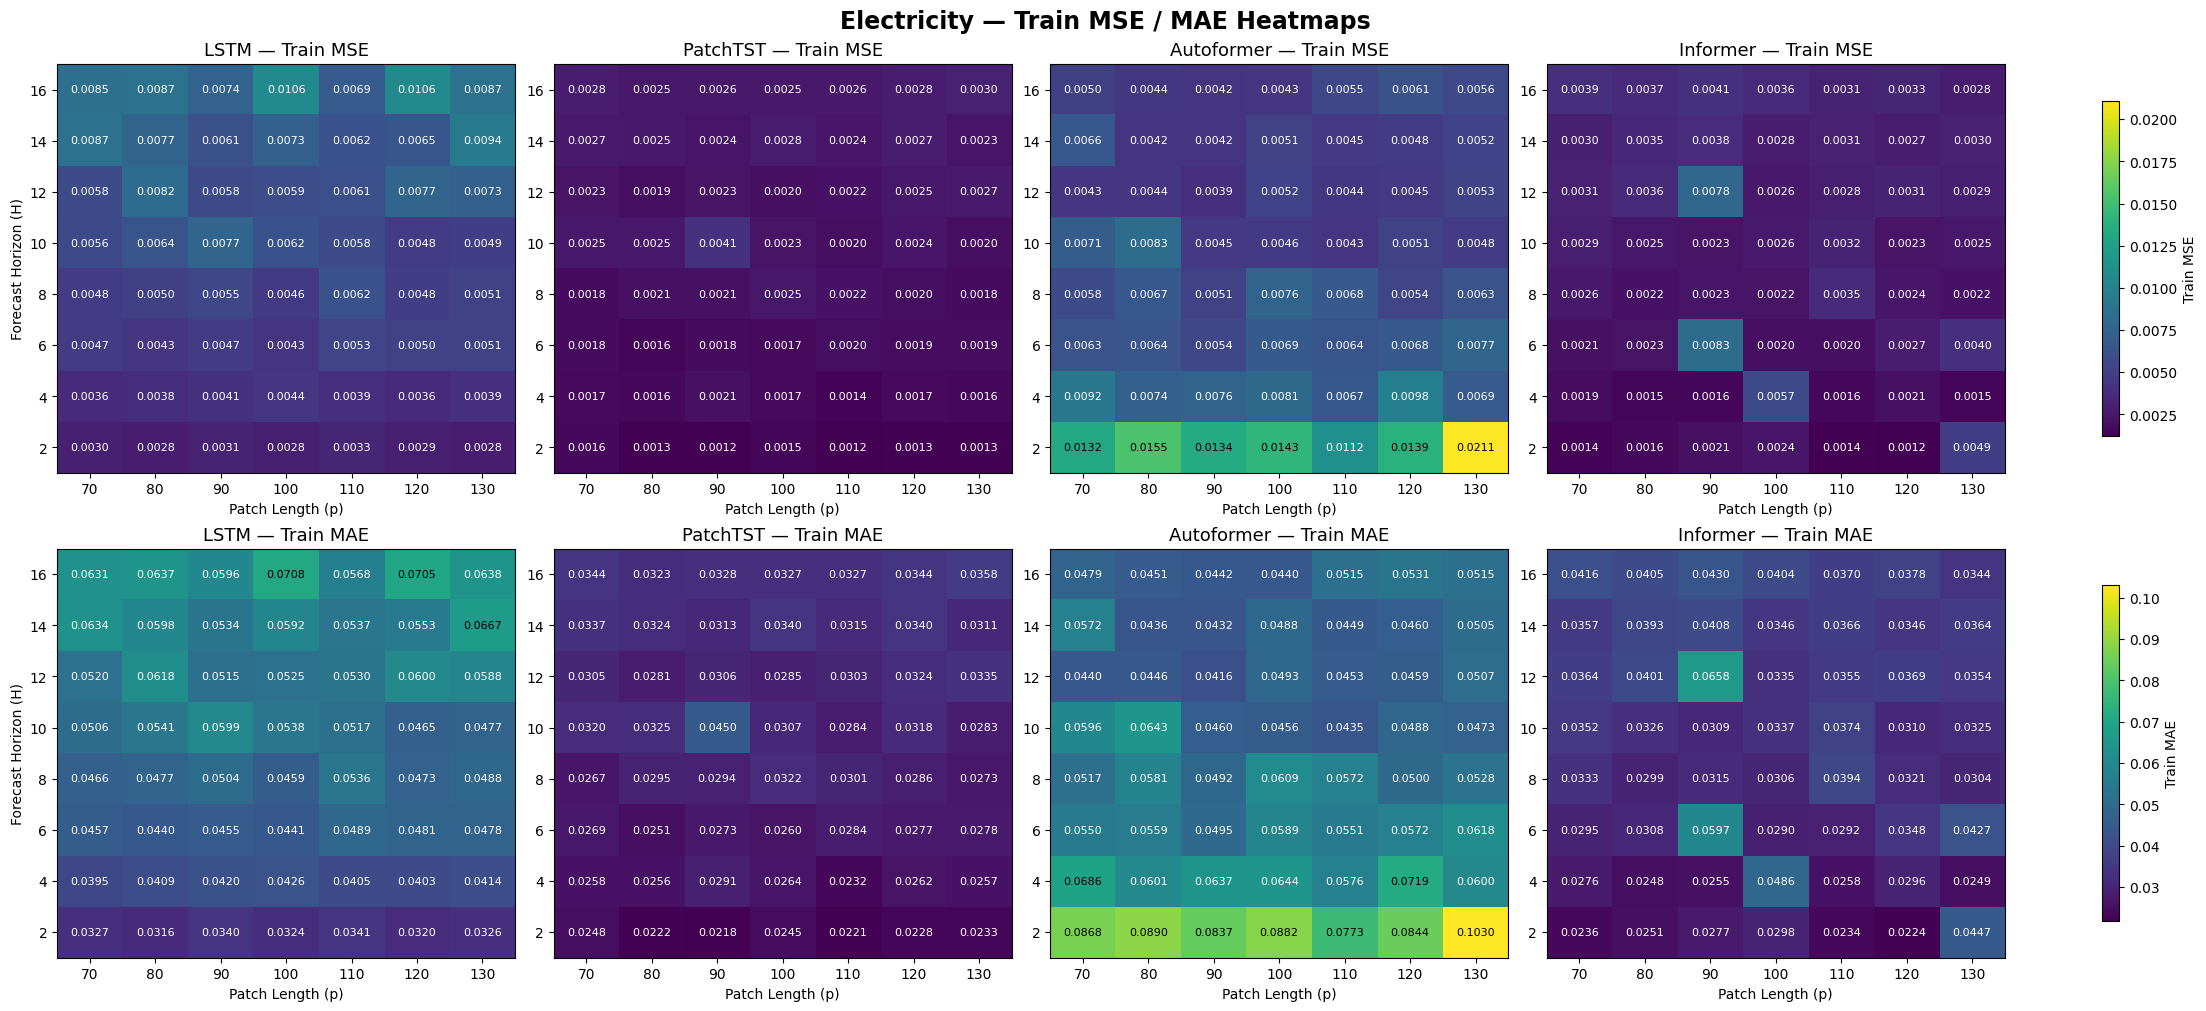

Saved: C:\Users\Win 11 New\Desktop\pa gk\experiments\04_electricity\results\electricity_grid_search_e4000\electricity_train_heatmaps.png


In [3]:
# 1. Khởi tạo các thông số
df = metrics_df.copy()

models = ["LSTM", "PatchTST", "Autoformer", "Informer"]
patches = [70, 80, 90, 100, 110, 120, 130]
horizons = [2, 4, 6, 8, 10, 12, 14, 16]

# 2. Chỉ lấy kết quả trên tập Train
train_df = df[df["Set"] == "Train"].copy()

# 3. Tạo figure gồm 2 hàng x 4 cột
fig, axes = plt.subplots(
    nrows=2,
    ncols=4,
    figsize=(22, 10),
    constrained_layout=True
)

metrics = ["MSE", "MAE"]

# 4. Vẽ heatmap cho từng metric
for row, metric in enumerate(metrics):

    # Dùng cùng thang màu cho cả 4 mô hình trong cùng 1 metric
    vmin = train_df[metric].min()
    vmax = train_df[metric].max()

    for col, model in enumerate(models):

        # Lọc dữ liệu theo model
        model_df = train_df[
            train_df["Model"] == model
        ]

        # Pivot thành ma trận:
        # hàng = Horizon, cột = PatchLen
        heatmap_data = model_df.pivot(
            index="Horizon",
            columns="PatchLen",
            values=metric
        ).reindex(index=horizons, columns=patches)

        values = heatmap_data.values

        # 5. Vẽ heatmap
        im = axes[row, col].imshow(
            values,
            cmap="viridis",
            aspect="auto",
            origin="lower",
            vmin=vmin,
            vmax=vmax
        )

        axes[row, col].set_title(
            f"{model} — Train {metric}",
            fontsize=13
        )

        axes[row, col].set_xticks(
            range(len(patches)),
            patches
        )

        axes[row, col].set_yticks(
            range(len(horizons)),
            horizons
        )

        axes[row, col].set_xlabel(
            "Patch Length (p)"
        )

        if col == 0:
            axes[row, col].set_ylabel(
                "Forecast Horizon (H)"
            )
        else:
            axes[row, col].set_ylabel("")

        # 6. Ghi số lên từng ô
        for i in range(values.shape[0]):      # hàng
            for j in range(values.shape[1]):  # cột

                val = values[i, j]

                # Chọn màu chữ để dễ nhìn
                norm_val = (
                    (val - vmin)
                    / (vmax - vmin + 1e-12)
                )

                text_color = (
                    "white" if norm_val < 0.55
                    else "black"
                )

                axes[row, col].text(
                    j, i,
                    f"{val:.4f}",
                    ha="center",
                    va="center",
                    fontsize=8,
                    color=text_color
                )

    # 7. Colorbar cho từng hàng metric
    fig.colorbar(
        im,
        ax=axes[row, :],
        label=f"Train {metric}",
        shrink=0.82
    )

fig.suptitle(
    "Electricity — Train MSE / MAE Heatmaps",
    fontsize=17,
    fontweight="bold"
)

# 8. Lưu hình
output_path = (
    RESULTS_DIR
    / "electricity_train_heatmaps.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", output_path)

Electricity — Test MSE / MAE Heatmaps

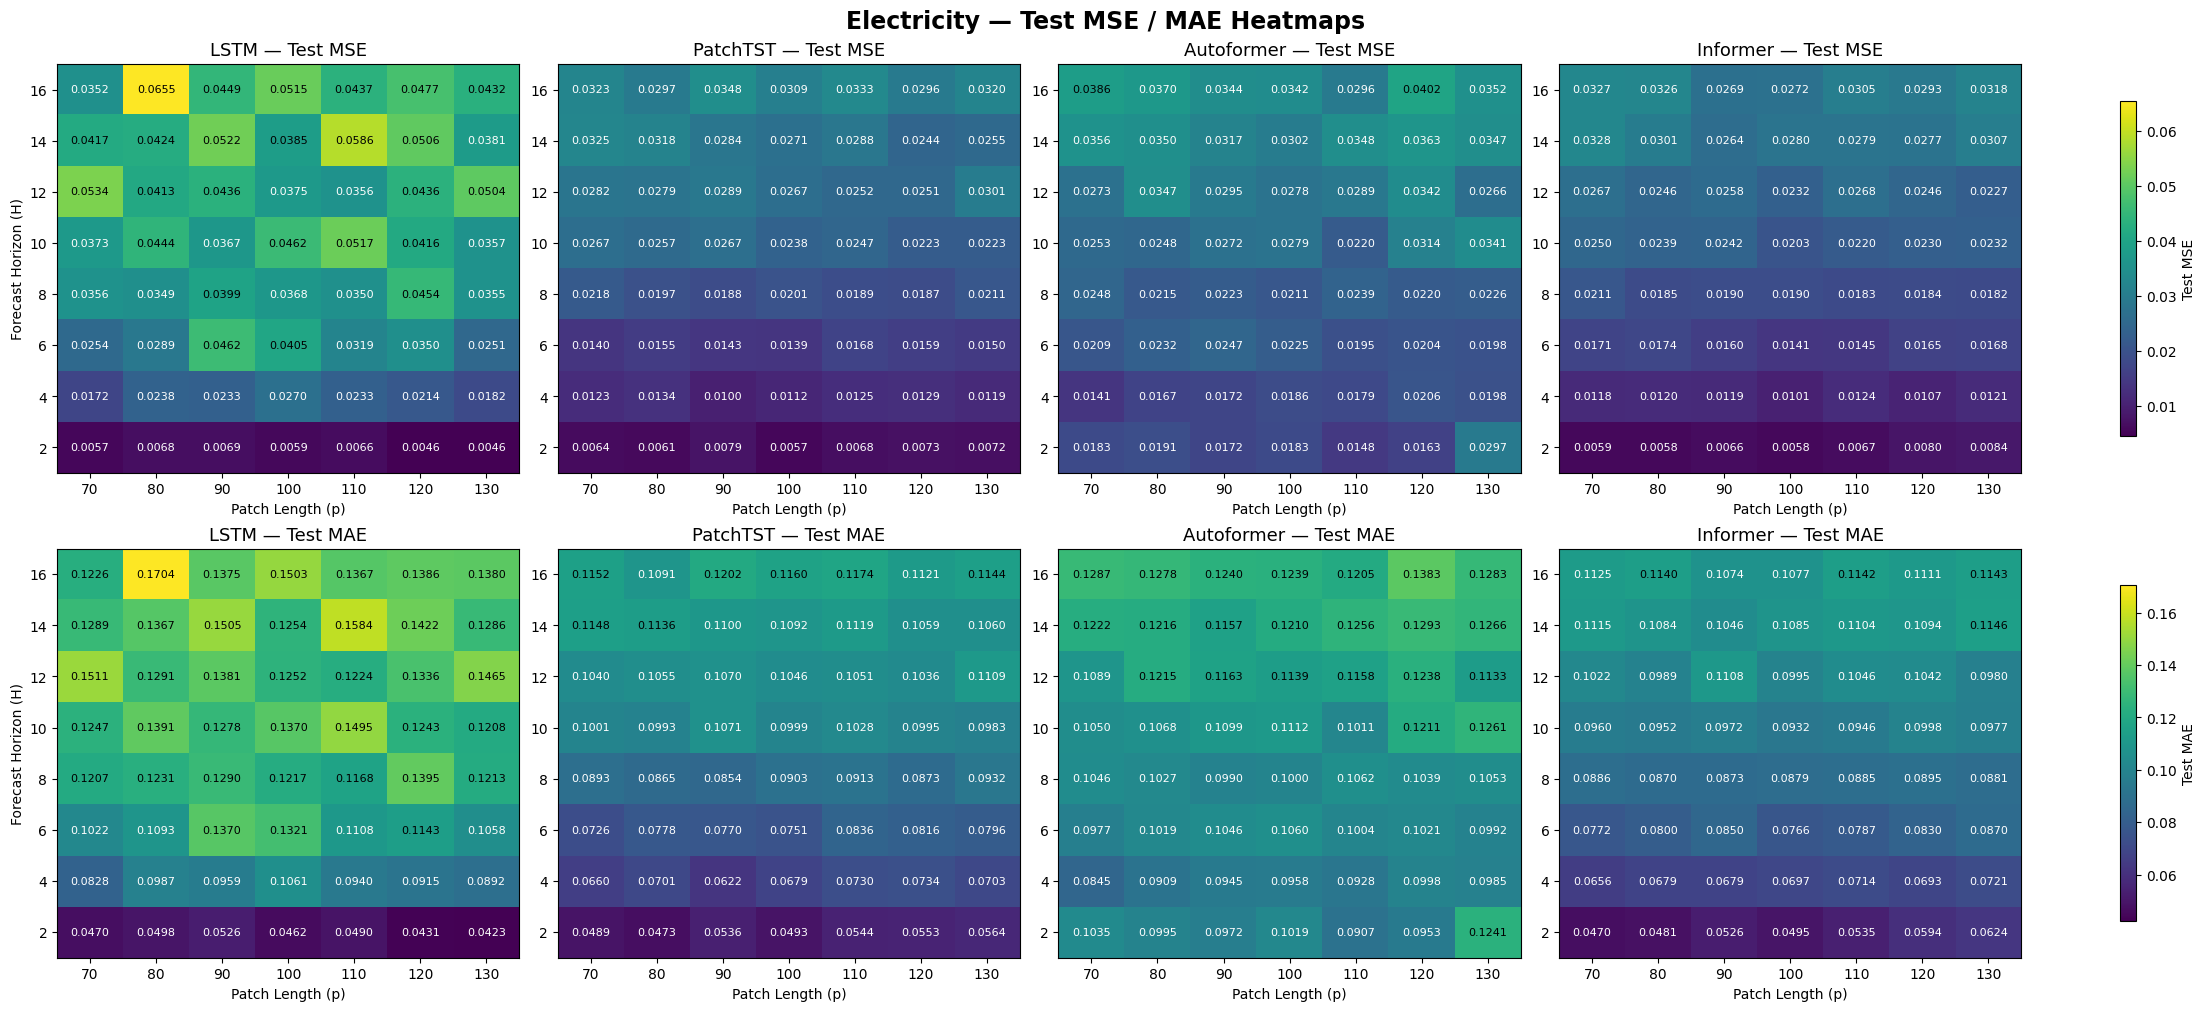

Saved: C:\Users\Win 11 New\Desktop\pa gk\experiments\04_electricity\results\electricity_grid_search_e4000\electricity_test_heatmaps.png


In [4]:
# 1. Chỉ lấy kết quả trên tập Test
test_df = df[df["Set"] == "Test"].copy()

# 2. Tạo figure gồm 2 hàng x 4 cột
fig, axes = plt.subplots(
    nrows=2,
    ncols=4,
    figsize=(22, 10),
    constrained_layout=True
)

metrics = ["MSE", "MAE"]

# 3. Vẽ heatmap cho từng metric
for row, metric in enumerate(metrics):

    # Dùng cùng thang màu cho cả 4 mô hình trong cùng 1 metric
    vmin = test_df[metric].min()
    vmax = test_df[metric].max()

    for col, model in enumerate(models):

        # Lọc dữ liệu theo model
        model_df = test_df[
            test_df["Model"] == model
        ]

        # Pivot thành ma trận:
        # hàng = Horizon, cột = PatchLen
        heatmap_data = model_df.pivot(
            index="Horizon",
            columns="PatchLen",
            values=metric
        ).reindex(index=horizons, columns=patches)

        values = heatmap_data.values

        # 4. Vẽ heatmap
        im = axes[row, col].imshow(
            values,
            cmap="viridis",
            aspect="auto",
            origin="lower",
            vmin=vmin,
            vmax=vmax
        )

        axes[row, col].set_title(
            f"{model} — Test {metric}",
            fontsize=13
        )

        axes[row, col].set_xticks(
            range(len(patches)),
            patches
        )

        axes[row, col].set_yticks(
            range(len(horizons)),
            horizons
        )

        axes[row, col].set_xlabel("Patch Length (p)")

        if col == 0:
            axes[row, col].set_ylabel("Forecast Horizon (H)")
        else:
            axes[row, col].set_ylabel("")

        # 5. Ghi số lên từng ô
        for i in range(values.shape[0]):
            for j in range(values.shape[1]):

                val = values[i, j]

                # Chọn màu chữ để dễ nhìn
                norm_val = (
                    (val - vmin)
                    / (vmax - vmin + 1e-12)
                )

                text_color = (
                    "white" if norm_val < 0.55
                    else "black"
                )

                axes[row, col].text(
                    j, i,
                    f"{val:.4f}",
                    ha="center",
                    va="center",
                    fontsize=8,
                    color=text_color
                )

    # 6. Colorbar cho từng hàng metric
    fig.colorbar(
        im,
        ax=axes[row, :],
        label=f"Test {metric}",
        shrink=0.82
    )

fig.suptitle(
    "Electricity — Test MSE / MAE Heatmaps",
    fontsize=17,
    fontweight="bold"
)

# 7. Lưu hình
output_path = (
    RESULTS_DIR
    / "electricity_test_heatmaps.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", output_path)

Ground Truth vs Predictions

Truth shape: (622, 48)
Prediction shape: (622, 48)


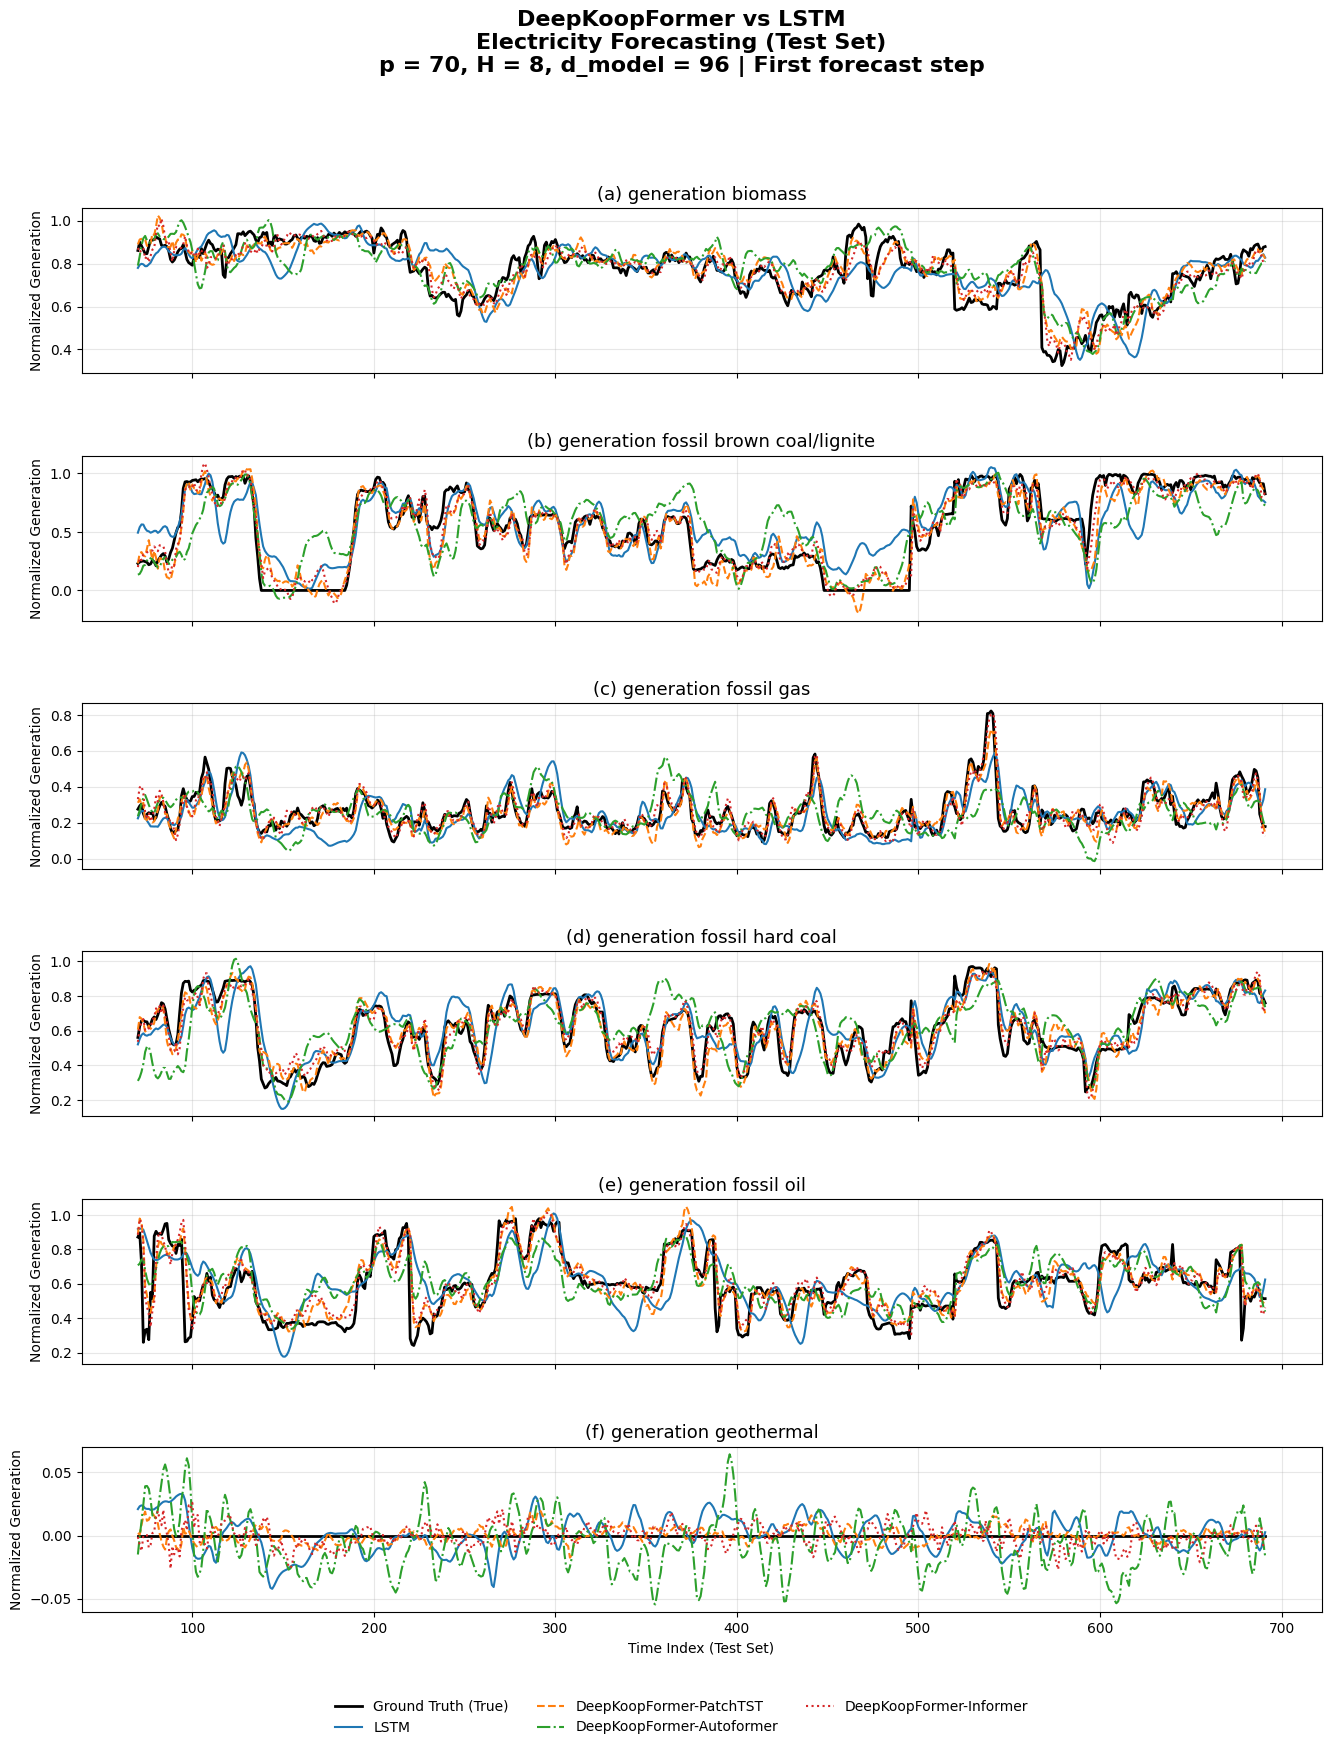

Saved: C:\Users\Win 11 New\Desktop\pa gk\experiments\04_electricity\results\electricity_grid_search_e4000\figure17_electricity_test_forecasts_p70_h8.png


In [8]:
# 1. Cấu hình Figure
p = 70
H = 8
d_model = 96

# Load dataset metadata
DATA_PATH = BASE_DIR / "data" / "electricity_train_test.pt"

bundle = torch.load(
    DATA_PATH,
    map_location="cpu",
    weights_only=False
)

channels = bundle["channels"]
num_channels = len(channels)

models = ["LSTM", "PatchTST", "Autoformer", "Informer"]

# 2. Load checkpoints
checkpoints = {}

for model in models:
    path = RESULTS_DIR / (
        f"{model.lower()}_p{p}_h{H}_d{d_model}.pt"
    )

    assert path.exists(), f"Missing checkpoint: {path}"

    ckpt = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    assert ckpt["data_hash"] == bundle["data_hash"]
    assert ckpt["patch_len"] == p
    assert ckpt["horizon"] == H

    checkpoints[model] = ckpt

# 3. Lấy dữ liệu dự báo trên tập Test
truth = checkpoints["LSTM"]["truth_test"].numpy()

predictions = {
    model: checkpoints[model]["pred_test"].numpy()
    for model in models
}

# Kiểm tra các mô hình sử dụng cùng Ground Truth
for model in models:
    np.testing.assert_allclose(
        checkpoints[model]["truth_test"].numpy(),
        truth
    )

    assert predictions[model].shape == truth.shape

assert truth.shape[1] == num_channels * H

print("Truth shape:", truth.shape)
print("Prediction shape:", predictions["PatchTST"].shape)

# 4. Style đồng bộ với Financial
styles = {
    "LSTM": {
        "color": "tab:blue",
        "linestyle": "-",
        "label": "LSTM"
    },
    "PatchTST": {
        "color": "tab:orange",
        "linestyle": "--",
        "label": "DeepKoopFormer-PatchTST"
    },
    "Autoformer": {
        "color": "tab:green",
        "linestyle": "-.",
        "label": "DeepKoopFormer-Autoformer"
    },
    "Informer": {
        "color": "tab:red",
        "linestyle": ":",
        "label": "DeepKoopFormer-Informer"
    }
}

# 5. Tạo Figure: 6 hàng x 1 cột
fig, axes = plt.subplots(
    nrows=num_channels,
    ncols=1,
    figsize=(16, 18),
    sharex=True
)

# Trục X: vị trí bước dự báo đầu tiên trong tập Test
sample_indices = np.arange(len(truth))
time_indices = sample_indices + p

for c in range(num_channels):
    ax = axes[c]

    # Flatten theo thứ tự channel-major:
    # [channel_0(t1...tH), channel_1(t1...tH), ...]
    idx = c * H

    # Ground Truth
    ax.plot(
        time_indices,
        truth[:, idx],
        color="black",
        linewidth=2,
        label="Ground Truth (True)"
    )

    # Dự báo của bốn mô hình
    for model in models:
        ax.plot(
            time_indices,
            predictions[model][:, idx],
            linewidth=1.5,
            **styles[model]
        )

    ax.set_title(
        f"({chr(97 + c)}) {channels[c]}",
        fontsize=13
    )

    ax.set_ylabel("Normalized Generation")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time Index (Test Set)")

# 6. Tiêu đề và legend chung
fig.suptitle(
    "DeepKoopFormer vs LSTM\n"
    "Electricity Forecasting (Test Set)\n"
    f"p = {p}, H = {H}, d_model = {d_model} | First forecast step",
    fontsize=16,
    fontweight="bold",
    y=0.99
)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.025),
    ncol=3,
    frameon=False
)

# Chừa khoảng trống cho tiêu đề và legend
fig.subplots_adjust(
    top=0.88,
    bottom=0.10,
    hspace=0.50
)

# 7. Lưu Figure
output_path = (
    RESULTS_DIR
     / "figure17_electricity_test_forecasts_p70_h8.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", output_path)

Electricity — Training Loss & Koopman Stability

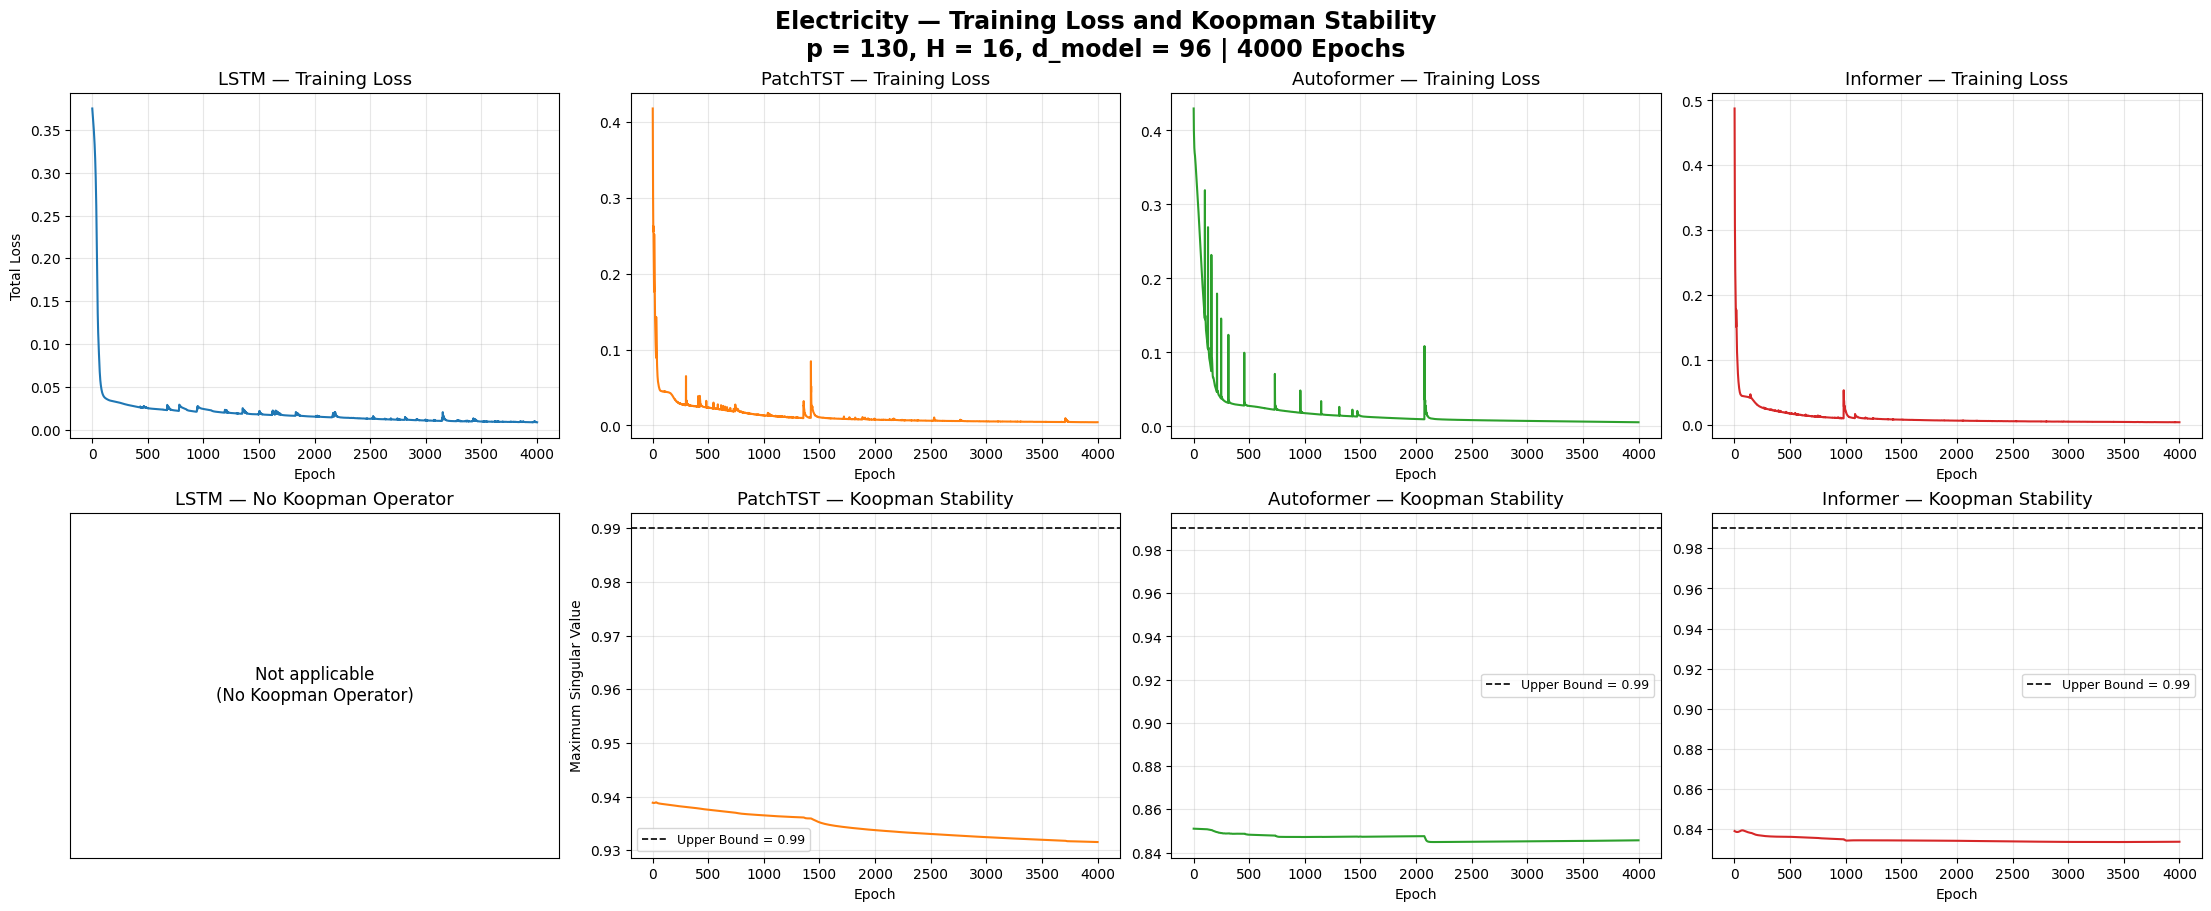

Saved: C:\Users\Win 11 New\Desktop\pa gk\experiments\04_electricity\results\electricity_grid_search_e4000\electricity_training_loss_koopman_stability.png

=== FINAL TRAINING DIAGNOSTICS ===
LSTM       | Final Loss: 0.008564
PatchTST   | Final Loss: 0.004256
Autoformer | Final Loss: 0.005704
Informer   | Final Loss: 0.003630


In [9]:
# 1. Cấu hình
p = 130
H = 16
d_model = 96

models = ["LSTM", "PatchTST", "Autoformer", "Informer"]

# 2. Load checkpoints
checkpoints = {}

for model in models:

    path = RESULTS_DIR / (
        f"{model.lower()}_p{p}_h{H}_d{d_model}.pt"
    )

    assert path.exists(), f"Missing checkpoint: {path}"

    ckpt = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    assert ckpt["patch_len"] == p
    assert ckpt["horizon"] == H
    assert ckpt["epochs"] == 4000

    checkpoints[model] = ckpt


# 3. Tạo Figure gồm 2 hàng x 4 cột
fig, axes = plt.subplots(
    nrows=2,
    ncols=4,
    figsize=(22, 9),
    constrained_layout=True
)

colors = {
    "LSTM": "tab:blue",
    "PatchTST": "tab:orange",
    "Autoformer": "tab:green",
    "Informer": "tab:red"
}


# 4. Vẽ Training Loss
for col, model in enumerate(models):

    ckpt = checkpoints[model]

    loss_history = np.asarray(
        ckpt["loss"]
    ).reshape(-1)

    epochs = np.arange(
        1, len(loss_history) + 1
    )

    ax = axes[0, col]

    ax.plot(
        epochs,
        loss_history,
        color=colors[model],
        linewidth=1.5
    )

    ax.set_title(
        f"{model} — Training Loss",
        fontsize=13
    )

    ax.set_xlabel("Epoch")

    if col == 0:
        ax.set_ylabel("Total Loss")

    ax.grid(True, alpha=0.3)

    ax.ticklabel_format(
        style="sci",
        axis="y",
        scilimits=(-3, 3)
    )


# 5. Vẽ Koopman Stability
for col, model in enumerate(models):

    ax = axes[1, col]

    if model == "LSTM":

        ax.text(
            0.5, 0.5,
            "Not applicable\n(No Koopman Operator)",
            ha="center",
            va="center",
            fontsize=12,
            transform=ax.transAxes
        )

        ax.set_title(
            "LSTM — No Koopman Operator",
            fontsize=13
        )

        ax.set_xticks([])
        ax.set_yticks([])

        continue

    ckpt = checkpoints[model]
    spectral_history = (
        np.asarray(ckpt["eig"]).reshape(-1) * 0.99
    )

    epochs = np.arange(
        1, len(spectral_history) + 1
    )

    ax.plot(
        epochs,
        spectral_history,
        color=colors[model],
        linewidth=1.5
    )

    # Giới hạn được thiết kế cho singular values
    ax.axhline(
        y=0.99,
        color="black",
        linestyle="--",
        linewidth=1.2,
        label="Upper Bound = 0.99"
    )

    ax.set_title(
        f"{model} — Koopman Stability",
        fontsize=13
    )

    ax.set_xlabel("Epoch")

    if col == 1:
        ax.set_ylabel("Maximum Singular Value")

    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9)


# 6. Tiêu đề Figure
fig.suptitle(
    "Electricity — Training Loss and Koopman Stability\n"
    f"p = {p}, H = {H}, d_model = {d_model} | 4000 Epochs",
    fontsize=17,
    fontweight="bold"
)


# 7. Lưu Figure
output_path = (
    RESULTS_DIR
    / "electricity_training_loss_koopman_stability.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", output_path)


# 8. Kiểm tra giá trị cuối cùng
print("\n=== FINAL TRAINING DIAGNOSTICS ===")

for model in models:

    ckpt = checkpoints[model]

    final_loss = np.asarray(
        ckpt["loss"]
    ).reshape(-1)[-1]

    print(
        f"{model:10s} | "
        f"Final Loss: {final_loss:.6f}"
    )

Electricity — Train Forecasts

Truth shape: (2722, 48)
Prediction shape: (2722, 48)


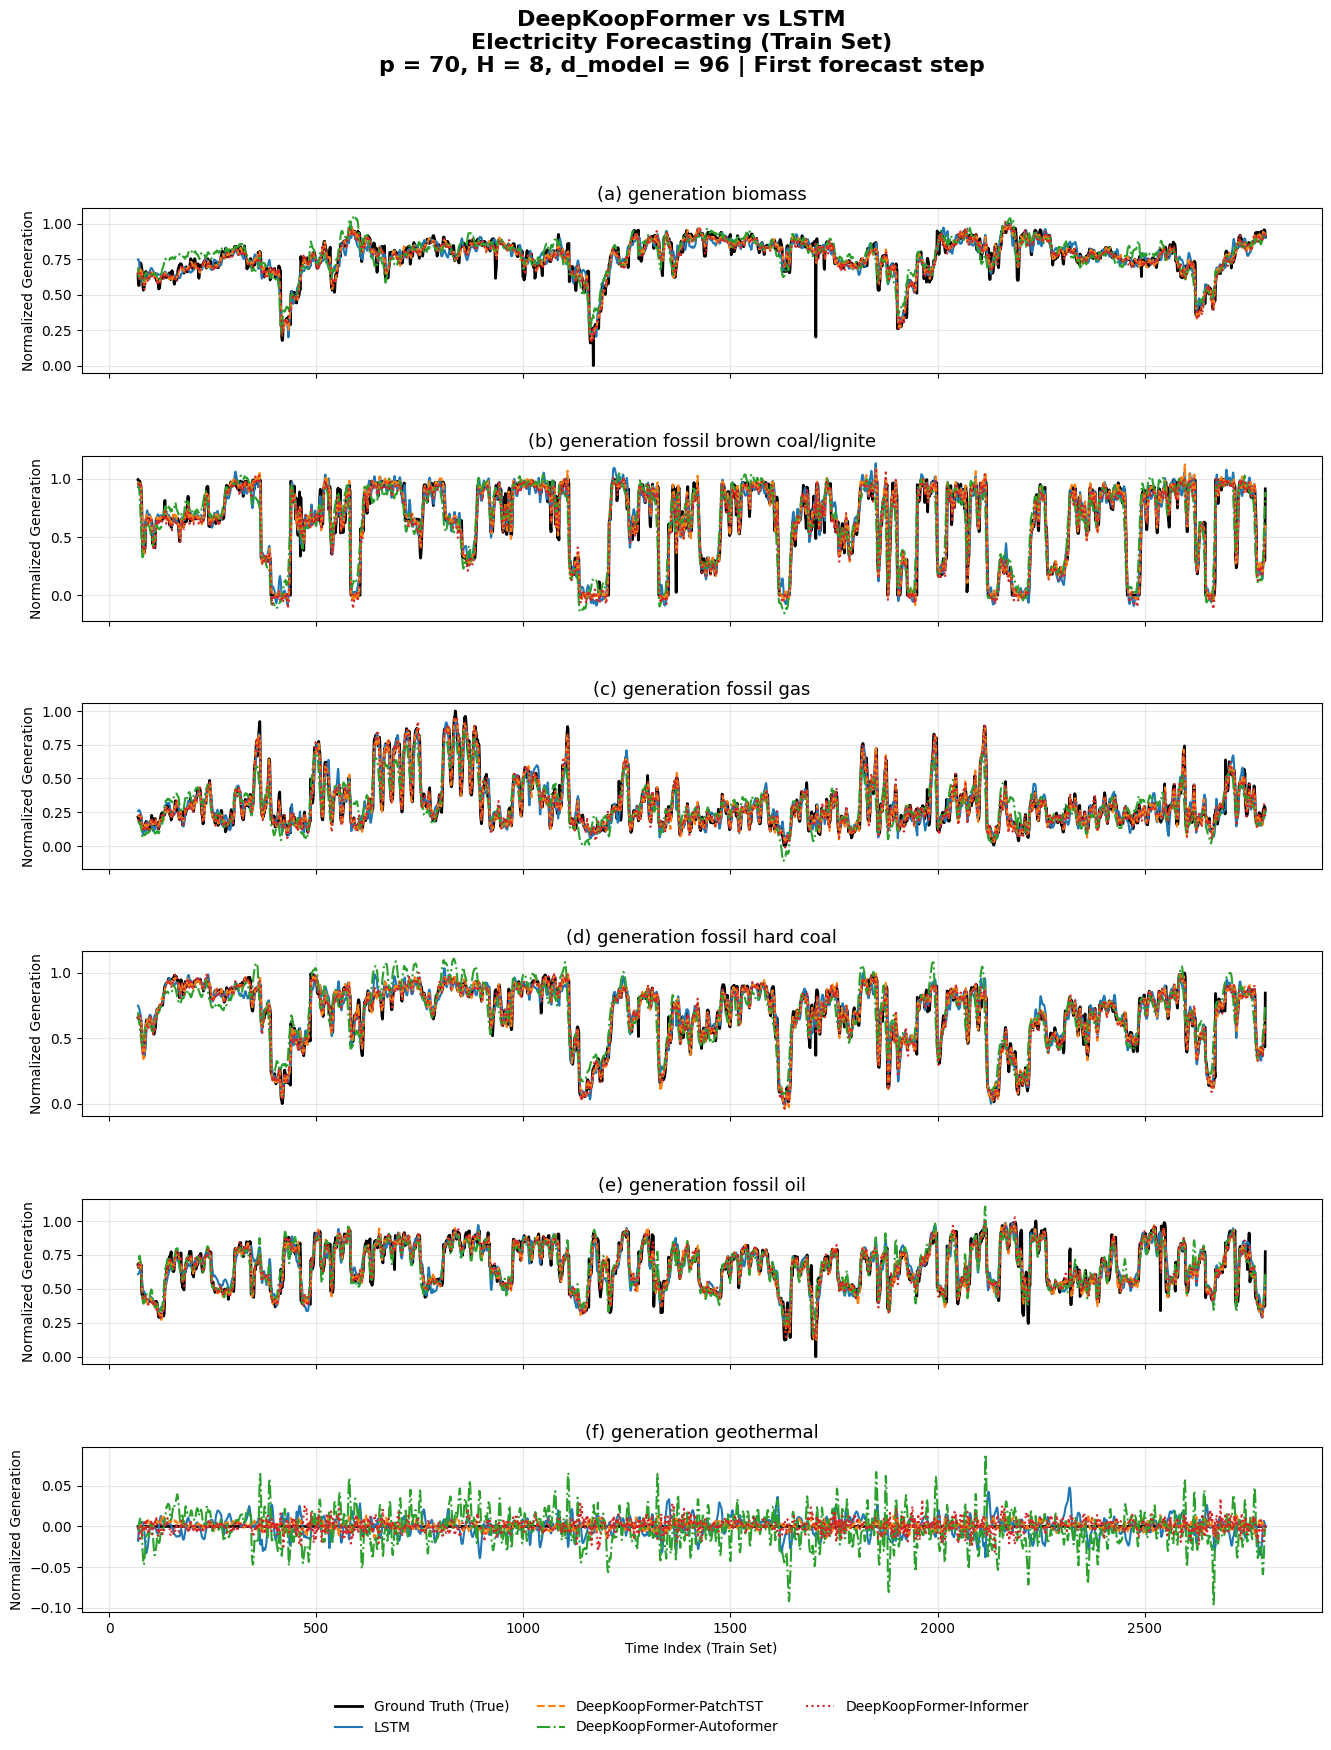

Saved: C:\Users\Win 11 New\Desktop\pa gk\experiments\04_electricity\results\electricity_grid_search_e4000\electricity_train_forecasts_p70_h8.png


In [10]:
# 1. Cấu hình giống Figure 17
p = 70
H = 8
d_model = 96

models = ["LSTM", "PatchTST", "Autoformer", "Informer"]

channels = bundle["channels"]
num_channels = len(channels)

# 2. Load checkpoints
train_checkpoints = {}

for model in models:

    path = RESULTS_DIR / (
        f"{model.lower()}_p{p}_h{H}_d{d_model}.pt"
    )

    assert path.exists(), f"Missing checkpoint: {path}"

    ckpt = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    assert ckpt["data_hash"] == bundle["data_hash"]
    assert ckpt["patch_len"] == p
    assert ckpt["horizon"] == H

    train_checkpoints[model] = ckpt

# 3. Lấy dự báo trên tập Train
truth_train = torch.as_tensor(
    train_checkpoints["LSTM"]["truth_train"]
).numpy()

predictions_train = {
    model: torch.as_tensor(
        train_checkpoints[model]["pred_train"]
    ).numpy()
    for model in models
}

for model in models:

    np.testing.assert_allclose(
        torch.as_tensor(
            train_checkpoints[model]["truth_train"]
        ).numpy(),
        truth_train
    )

    assert predictions_train[model].shape == truth_train.shape

assert truth_train.shape[1] == num_channels * H

print("Truth shape:", truth_train.shape)
print("Prediction shape:", predictions_train["PatchTST"].shape)

# 4. Style đồng bộ với Figure 17
styles = {
    "LSTM": {
        "color": "tab:blue",
        "linestyle": "-",
        "label": "LSTM"
    },
    "PatchTST": {
        "color": "tab:orange",
        "linestyle": "--",
        "label": "DeepKoopFormer-PatchTST"
    },
    "Autoformer": {
        "color": "tab:green",
        "linestyle": "-.",
        "label": "DeepKoopFormer-Autoformer"
    },
    "Informer": {
        "color": "tab:red",
        "linestyle": ":",
        "label": "DeepKoopFormer-Informer"
    }
}

# 5. Tạo Figure gồm 6 subplot
fig, axes = plt.subplots(
    nrows=num_channels,
    ncols=1,
    figsize=(16, 18),
    sharex=True
)

sample_indices = np.arange(len(truth_train))
time_indices = sample_indices + p

for c in range(num_channels):

    ax = axes[c]

    # Channel-major:
    # [channel_0(t1...tH), channel_1(t1...tH), ...]
    idx = c * H

    # Ground Truth
    ax.plot(
        time_indices,
        truth_train[:, idx],
        color="black",
        linewidth=2,
        label="Ground Truth (True)"
    )

    # Dự báo của 4 mô hình
    for model in models:

        ax.plot(
            time_indices,
            predictions_train[model][:, idx],
            linewidth=1.5,
            **styles[model]
        )

    ax.set_title(
        f"({chr(97 + c)}) {channels[c]}",
        fontsize=13
    )

    ax.set_ylabel("Normalized Generation")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time Index (Train Set)")

# 6. Tiêu đề và Legend chung
fig.suptitle(
    "DeepKoopFormer vs LSTM\n"
    "Electricity Forecasting (Train Set)\n"
    f"p = {p}, H = {H}, d_model = {d_model} | First forecast step",
    fontsize=16,
    fontweight="bold",
    y=0.99
)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.025),
    ncol=3,
    frameon=False
)

fig.subplots_adjust(
    top=0.88,
    bottom=0.10,
    hspace=0.50
)

# 7. Lưu hình
output_path = (
    RESULTS_DIR
    / "electricity_train_forecasts_p70_h8.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", output_path)

Electricity — Author-style Training Diagnostics

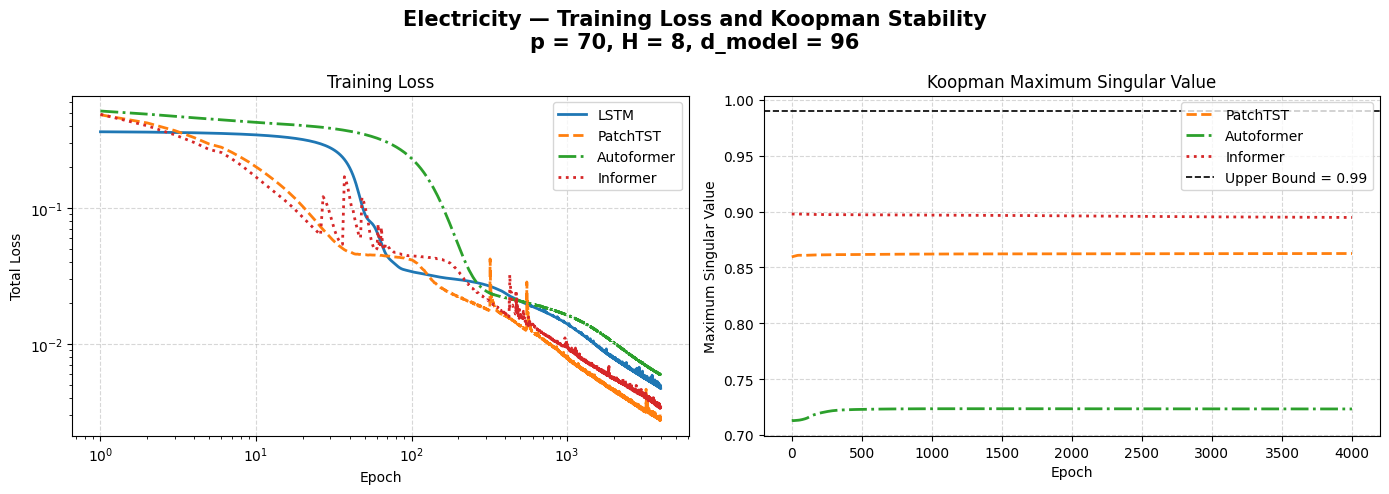

Saved: C:\Users\Win 11 New\Desktop\pa gk\experiments\04_electricity\results\electricity_grid_search_e4000\electricity_training_diagnostics_p70_h8.png


In [11]:
# 1. Cấu hình
p = 70
H = 8
d_model = 96

models = ["LSTM", "PatchTST", "Autoformer", "Informer"]

colors = {
    "LSTM": "tab:blue",
    "PatchTST": "tab:orange",
    "Autoformer": "tab:green",
    "Informer": "tab:red"
}

linestyles = {
    "LSTM": "-",
    "PatchTST": "--",
    "Autoformer": "-.",
    "Informer": ":"
}

# 2. Load checkpoints
checkpoints = {}

for model in models:

    path = RESULTS_DIR / (
        f"{model.lower()}_p{p}_h{H}_d{d_model}.pt"
    )

    assert path.exists(), path

    ckpt = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    assert ckpt["data_hash"] == bundle["data_hash"]
    assert ckpt["epochs"] == 4000

    checkpoints[model] = ckpt

# 3. Figure gồm hai subplot
fig, (ax1, ax2) = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 5)
)

# 4. Training Loss
for model in models:

    loss_history = torch.as_tensor(
        checkpoints[model]["loss"]
    ).numpy().reshape(-1)

    epochs = np.arange(1, len(loss_history) + 1)

    ax1.plot(
        epochs,
        loss_history,
        color=colors[model],
        linestyle=linestyles[model],
        linewidth=2,
        label=model
    )

ax1.set_xscale("log")
ax1.set_yscale("log")

ax1.set_title("Training Loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Total Loss")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend()

# 5. Koopman Maximum Singular Value
for model in models:

    if model == "LSTM":
        continue

    # Checkpoint lưu max(sigmoid(S_raw))
    # Singular values thực tế = 0.99 * sigmoid(S_raw)
    raw_history = torch.as_tensor(
        checkpoints[model]["eig"]
    ).numpy().reshape(-1)

    singular_history = 0.99 * raw_history

    epochs = np.arange(1, len(singular_history) + 1)

    ax2.plot(
        epochs,
        singular_history,
        color=colors[model],
        linestyle=linestyles[model],
        linewidth=2,
        label=model
    )

ax2.axhline(
    0.99,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Upper Bound = 0.99"
)

ax2.set_title("Koopman Maximum Singular Value")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Maximum Singular Value")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend()

# 6. Tiêu đề
fig.suptitle(
    "Electricity — Training Loss and Koopman Stability\n"
    f"p = {p}, H = {H}, d_model = {d_model}",
    fontsize=15,
    fontweight="bold"
)

fig.tight_layout()

# 7. Lưu Figure
output_path = (
    RESULTS_DIR
    / "electricity_training_diagnostics_p70_h8.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", output_path)